In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score, RocCurveDisplay

sns.set_theme(style="darkgrid")
print(f"XGBoost version: {xgb.__version__} ✅")

XGBoost version: 3.2.0 ✅


In [3]:
cols = ['label',
        'lepton_pT', 'lepton_eta', 'lepton_phi',
        'missing_energy_magnitude', 'missing_energy_phi',
        'jet1pt', 'jet1eta', 'jet1phi', 'jet1b_tag',
        'jet2pt', 'jet2eta', 'jet2phi', 'jet2b_tag',
        'jet3pt', 'jet3eta', 'jet3phi', 'jet3b_tag',
        'jet4pt', 'jet4eta', 'jet4phi', 'jet4b_tag',
        'mjj', 'mjjj', 'mlv', 'mjlv', 'mbb', 'mwbb', 'mwwbb']

df = pd.read_csv('../data/HIGGS.csv', header=None, names=cols, nrows=500000)

X = df.drop('label', axis=1)
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape[0]} rows")
print(f"Test:  {X_test.shape[0]} rows ✅")

Train: 400000 rows
Test:  100000 rows ✅


In [4]:
xgb_model = xgb.XGBClassifier(
    n_estimators=2000,        # more trees
    max_depth=8,              # was 6 — deeper trees catch more patterns
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,       # prevents overfitting
    gamma=0.1,                # prevents overfitting
    eval_metric='auc',
    early_stopping_rounds=50, # stops automatically when AUC stops improving
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=100
)

print("Training done ✅")

[0]	validation_0-auc:0.73671
[100]	validation_0-auc:0.81235
[200]	validation_0-auc:0.81895
[300]	validation_0-auc:0.82163
[400]	validation_0-auc:0.82339
[500]	validation_0-auc:0.82458
[600]	validation_0-auc:0.82544
[700]	validation_0-auc:0.82599
[800]	validation_0-auc:0.82632
[900]	validation_0-auc:0.82654
[1000]	validation_0-auc:0.82671
[1100]	validation_0-auc:0.82690
[1166]	validation_0-auc:0.82689
Training done ✅


In [5]:
y_pred = xgb_model.predict(X_test)
y_prob = xgb_model.predict_proba(X_test)[:, 1]

xgb_auc = roc_auc_score(y_test, y_prob)
xgb_acc = accuracy_score(y_test, y_pred)

print(f"XGBoost")
print(f"  Accuracy : {xgb_acc:.4f}")
print(f"  AUC-ROC  : {xgb_auc:.4f}")

XGBoost
  Accuracy : 0.7452
  AUC-ROC  : 0.8269


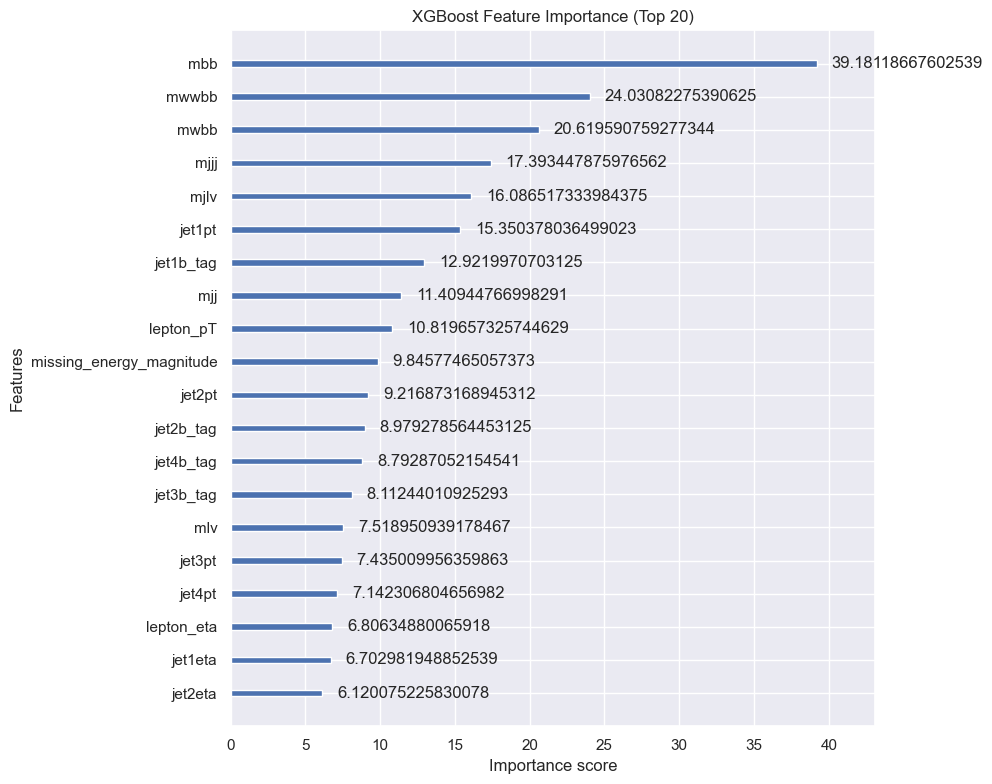

In [6]:
fig, ax = plt.subplots(figsize=(10, 8))

xgb.plot_importance(xgb_model, ax=ax, max_num_features=20, 
                    importance_type='gain')
ax.set_title('XGBoost Feature Importance (Top 20)')
plt.tight_layout()
plt.savefig('../plots/xgb_feature_importance.png', dpi=150)
plt.show()

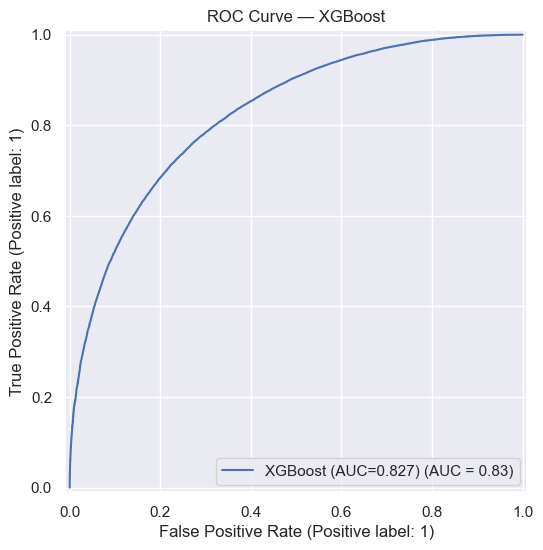

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(y_test, y_prob,
    name=f"XGBoost (AUC={xgb_auc:.3f})", ax=ax)

ax.set_title("ROC Curve — XGBoost")
plt.savefig('../plots/roc_xgboost.png', dpi=150)
plt.show()

In [8]:
import joblib

joblib.dump(xgb_model, '../models/xgboost.pkl')
print("XGBoost saved ✅")

XGBoost saved ✅


## XGBoost Results

| Model | Accuracy | AUC-ROC |
|-------|----------|---------|
| Logistic Regression | 0.6410 | 0.6845 |
| Random Forest       | 0.7287 | 0.8078 |
| XGBoost             | 0.7452   | 0.8269   |


XGBoost achieves AUC-ROC of 0.8269, improving over Random Forest (0.8078)
but showing diminishing returns despite increasing tree depth and count.
The model converged around 800-900 trees with early stopping, suggesting
the gradient boosting approach has reached its practical limit on this
feature set.

This motivates moving to neural networks, which can learn complex
non-linear interactions between features that tree-based methods
cannot capture as effectively.